This notebook extracts and analyses autoradiography data for AMPA and NMDA receptor densities.
It also compares these receptors with the cortical hierarchy and plots any correlations between them.
It makes use of ReceptorNames, RegionNames, ReceptData files from the original repo of Hansen et al. Nature Neuroscience (2022),
that can be found on the associated repo at https://github.com/netneurolab/hansen_receptors/tree/main/data/autoradiography.
It also uses the function from the same repo called make_autorad_schaefer100, that converts the parcellation used
in the original publication for autoradiography: https://www.frontiersin.org/journals/neuroanatomy/articles/10.3389/fnana.2017.00078/full#supplementary-material to Schaefer 100.
This notebook also produces the autoradiography data for Schaefer 100 to be used in the model at ../../data/processed/autorad_schaefer100_LH_NMDA_rd.csv and ../../data/processed/autorad_schaefer100_LH_AMPA_rd.csv.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pearsonr, zscore
import scienceplots
from netneurotools import datasets
from nilearn.datasets import fetch_atlas_schaefer_2018
from nibabel.freesurfer.io import read_annot
plt.style.use(['science', 'nature'])
import seaborn as sns
from matplotlib.colors import ListedColormap
plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 27,
    "axes.linewidth": 1.5,
    "axes.titlesize": 30,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.title_fontsize": 15,
    "legend.fontsize": 20,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

colors = {
    "ampa":   "#3182bd",  # dark blue
    "nmda":   "#f89f84",  # dark red
    "ratio":  "#6a51a3",  # ratio cmap
    "grey":   "#4d4d4d",  # neutral line/axis color
}

# AMPA sequential (blue)
ampa_cmap = LinearSegmentedColormap.from_list( "ampa_seq", ["#deebf7", "#9ecae1", "#3182bd"], N=256)

# NMDA sequential (red)
nmda_cmap = LinearSegmentedColormap.from_list( "nmda_seq", ["#fee0d2", "#f89f84", "#de2d26"], N=256)

# NMDA/AMPA ratio diverging
ratio_cmap = LinearSegmentedColormap.from_list(
    "ratio_seq",
    ["#f2f0f7", "#cbc9e2", "#6a51a3"], # light to dark purple
    N=256,
)

## Function to convert from autorad parcellation to Schaefer 100

In [2]:
# Function from Hansen et al., Nature Neuroscience (2022)
def make_autorad_schaefer100(autorad_zilles44):
    
    autorad_schaefer100 = np.zeros((50, autorad_zilles44.shape[1]))
    # mapping between zilles and schaefer (done manually), numbers are indices in the autoradiography list (36 is at index 21), then index of where it is in the list is the index in schaefer
    zilles44_to_schaefer100 = \
        [[21],  # area '36' // 0
         [9],   # area 'V3v' // 1
         [6],   # area 'V2v' // 2
         [4, 6],   # area 'V1', 'V2v'  // 3
         [4, 5, 6],   # area 'V1', 'V2v', 'V2d' // 4
         [4],   # area 'V1' // 5
         [np.nan],  # // 6
         [8, 7],   # area 'V3d', 'V3a' // 7
         [8],   # area 'V3d' // 8
         [17],  # area '42' // 9
         [16],  # area '41' // 10
         [np.nan], # // 11
         [0, 3, 2],  # area '1', '3b', '3a' \\ 12
         [0, 3, 2],  # area '1', '3b', '3a' \\ 13
         [0, 3, 2],  # area '1', '3b', '3a'\\ 14
         [14],  # area '37L' \\ 15
         [27, 1],  # area 'PFt', '2' \\ 16
         [np.nan],  # // 17
         [1],  # area '2' // 18
         [24],  # area '5M' // 19
         [23],  # area '5L' // 20
         [0, 34],  # area '1', '6' // 21
         [35],  # area '8' // 22
         [28, 27],  # area 'PFm', 'PFt' // 23
         [np.nan],  # insula // 24
         [41],  # area '45' // 25
         [36],  # area '9' // 26
         [29],  # area '24' // 27
         [24],  # area '5M' // 28
         [35],  # area '8' // 29
         [39],  # area '11' // 30
         [22],  # area '38' // 31
         [18],  # area '20' // 32
         [28, 27],  # area 'PFm' 'PFt' // 33
         [42],  # area '46' // 34
         [7],  # area 'V3A' // 35
         [31],  # area '23' (and 31?) // 36
         [20, 19],  # area '22', '21' // 37
         [19, 20],  # area '21', '22' // 38
         [19, 20],  # area '21', '22' // 39
         [25, 26],  # area 'PGa', 'PGp' // 40
         [43],  # area '47' // 41
         [41, 43, 42],  # area '45', '47', '46' // 42
         [29, 30, 38],  # area '24', '32', '10M' // 43
         [37],  # area '10L' // 44
         [36],  # area '9' // 45
         [35, 36],  # area '8', '9' // 46
         [35],  # area '8' // 47
         [32],  # area '31' // 48
         [32]]  # area '31' // 49 

    # Iterate through each brain region in schaefer 100 -> only 50 regions
    for n in range(autorad_schaefer100.shape[0]):
        if np.isnan(zilles44_to_schaefer100[n][0]): # If the element in the conversion matrix is nan, then make all receptor values for that region to be nan -> missing data for that region
            autorad_schaefer100[n, :] = np.nan
        elif len(zilles44_to_schaefer100[n]) == 1: # If the length of the list at the brain region index in the schaefer is 1
            autorad_schaefer100[n, :] = autorad_zilles44[zilles44_to_schaefer100[n], :] # For index n, fill in with values at index zilles44_to_schaefer100[n] from the original data
        elif len(zilles44_to_schaefer100[n]) > 1: # If there are multiple areas in the original parcellation corresponding to area n in the schaefer parcellation
            # print('indices:', zilles44_to_schaefer100[n])
            autorad_schaefer100[n, :] = np.mean(autorad_zilles44[zilles44_to_schaefer100[n], :], axis=0).T
            # print('original vals:', autorad_zilles44[zilles44_to_schaefer100[n], :])
            # print('mean:', autorad_schaefer100[n, :])

    return autorad_schaefer100

## Define autoradiography data for AMPA and NMDA for the left hemisphere

In [3]:

receptor_names = np.load('../../data/raw/hansen_data/ReceptorNames.npy')
region_names = np.load('../../data/raw/hansen_data/RegionNames.npy')
print('Receptor names:', receptor_names)
receptor_data = np.load('../../data/raw/hansen_data/ReceptData.npy')
schaefer = fetch_atlas_schaefer_2018(n_rois=100)
autorad_schaefer100 = make_autorad_schaefer100(receptor_data)
print(f'AMPA receptor data: {receptor_data[:, 0]}')
# To verify that these numbers match the original values in the autoradiography data, check Supplementary Table 2 in
# https://www.frontiersin.org/journals/neuroanatomy/articles/10.3389/fnana.2017.00078/full#supplementary-material
# There, for example we can see the AMPA value in V1 which is at index 4 is 496 and the one in V2v which is at index 6 is 472
# Similar for NMDA, so we can check that the values in these matrices are correct.
# e.g. V1 is at index 5 in Schaefer100
ampa_rd_LH = np.zeros(50)
ampa_rd_LH[:] = autorad_schaefer100[:, 0] # AMPA receptor density for left hemisphere
print(f'AMPA schaefer100: {ampa_rd_LH}')
nmda_rd_autorad_LH = np.zeros(50)
nmda_rd_autorad_LH[:] = autorad_schaefer100[:, 1] # NMDA receptor density for left hemisphere
nmda_to_ampa = nmda_rd_autorad_LH / ampa_rd_LH # NMDA/AMPA ratio

Receptor names: ['AMPA' 'NMDA' 'kainate' 'GABAa' 'GABAa/BZ' 'GABAb' 'm1' 'm2' 'm3' 'a4b2'
 'a1' 'a2' '5-HT1a' '5-HT2' 'D1']
[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/schaefer_2018
AMPA receptor data: [443. 478. 473. 455. 496. 451. 472. 534. 478. 477. 383. 623. 656. 533.
 506. 513. 479. 498. 584. 618. 506. 638. 715. 366. 382. 377. 421. 485.
 513. 509. 383. 364. 400. 286. 301. 654. 647. 663. 714. 791. 492. 472.
 644. 689.]
AMPA schaefer100: [638.         477.         472.         484.         473.
 496.                  nan 506.         478.         498.
 479.                  nan 457.         457.         457.
 506.         481.5                 nan 478.         382.
 366.         372.         654.         499.                  nan
 472.         647.         509.         382.         654.
 791.         715.         584.         499.         644.
 534.         364.         562.         562.         562.
 399.         689.         601.66666667 535.33333333 663.
 647.   

## Plot map of NMDA / AMPA receptor ratio

In [ ]:
import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42 # embed TrueType, not Type3
mpl.rcParams["ps.fonttype"] = 42

schaefer = fetch_atlas_schaefer_2018(n_rois=100)
annot = datasets.fetch_schaefer2018('fsaverage')['100Parcels7Networks']
nnodes = len(schaefer['labels'])

import nibabel.freesurfer as fs
from nilearn import plotting, datasets
from scipy.special import erf
from nibabel.freesurfer.io import read_annot
# First define the atlas
annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)
mapped_nmda_to_ampa = np.zeros_like(labels, dtype=float)
# Fill the map with the receptor ratio values
for i in range(len(region_names)):
    if i == 0:
        mapped_nmda_to_ampa[labels == i] = np.nan
    else:
        mapped_nmda_to_ampa[labels == i] = nmda_to_ampa[i - 1]
vmin, vmax = np.nanmin(mapped_nmda_to_ampa), np.nanmax(mapped_nmda_to_ampa)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_nmda_to_ampa, fs.sulc_left,
        hemi='left', view=view, cmap=ratio_cmap,
        colorbar=True, symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig, engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/autoradiography_nmda_ampa_schaefer100/nmda_ampa_ratio_schaefer100_{view}.{ext}', dpi=dpi, bbox_inches='tight')
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/schaefer_2018
Please cite the following papers if you are using this function:
  [primary]:
    Alexander Schaefer, Ru Kong, Evan M Gordon, Timothy O Laumann, Xi-Nian Zuo, Avram J Holmes, Simon B Eickhoff, and BT Thomas Yeo. Local-global parcellation of the human cerebral cortex from intrinsic functional connectivity mri. Cerebral cortex, 28(9):3095–3114, 2018.
Dataset atl-schaefer2018 already exists. Skipping download.
[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Plot map of AMPA receptor densities

In [5]:
import nibabel.freesurfer as fs
from nilearn import plotting, datasets
from scipy.special import erf
from nibabel.freesurfer.io import read_annot

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

ampa_rd_LH_norm = ampa_rd_LH / max(ampa_rd_LH)

mapped_ampa = np.zeros_like(labels, dtype=float)
for i in range(len(region_names)):
    if i == 0:
        mapped_ampa[labels == i] = np.nan
    else:
        mapped_ampa[labels == i] = ampa_rd_LH_norm[i - 1]
vmin, vmax = np.nanmin(mapped_ampa), np.nanmax(mapped_ampa)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_ampa, fs.sulc_left,
        hemi='left', view=view, cmap=ampa_cmap,
        colorbar=True, symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig, engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/autoradiography_nmda_ampa_schaefer100/ampa_rd_schaefer100_{view}.{ext}', dpi=dpi, transparent=True)
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Plot map of NMDA from autorad receptor densities


In [6]:
import nibabel.freesurfer as fs
from nilearn import plotting, datasets
from scipy.special import erf
from nibabel.freesurfer.io import read_annot

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

nmda_rd_autorad_LH_norm = nmda_rd_autorad_LH / max(nmda_rd_autorad_LH)

mapped_nmda_autorad = np.zeros_like(labels, dtype=float)
for i in range(len(region_names)):
    if i == 0:
        mapped_nmda_autorad[labels == i] = np.nan
    else:
        mapped_nmda_autorad[labels == i] = nmda_rd_autorad_LH_norm[i - 1]
vmin, vmax = np.nanmin(mapped_nmda_autorad), np.nanmax(mapped_nmda_autorad)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_nmda_autorad, fs.sulc_left,
        hemi='left', view=view, cmap=nmda_cmap,
        colorbar=True, symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig, engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/autoradiography_nmda_ampa_schaefer100/nmda_autorad_rd_schaefer100_{view}.{ext}', dpi=dpi, transparent=True)
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Load hierarchy for left hemisphere

In [4]:
hierarchy_LH_schaefer_100 = pd.read_csv('../../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val'].tolist()[:50]

## Clean nans from NMDA, AMPA and NMDA/AMPA ratio lists

In [5]:
indices_nan = []
for index, nmda_ampa_val in enumerate(nmda_to_ampa):
    if np.isnan(nmda_ampa_val):
        indices_nan.append(index)
nmda_autorad_LH_no_nans = np.array([val for index, val in enumerate(nmda_rd_autorad_LH) if index not in indices_nan])
nmda_to_ampa_LH_no_nans = np.array([val for index, val in enumerate(nmda_to_ampa) if index not in indices_nan])
hierarchy_LH_schaefer_100_no_nans = np.array([val for index, val in enumerate(hierarchy_LH_schaefer_100) if index not in indices_nan])
ampa_autorad_LH_no_nans = np.array([val for index, val in enumerate(ampa_rd_LH) if index not in indices_nan])

## NMDA Receptor Density vs. Hierarchy

In [13]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})


In [7]:
indices_nan

[6, 11, 17, 24]

In [25]:
region_labels_LH = [lbl.decode() if isinstance(lbl, bytes) else lbl
                    for lbl in schaefer['labels'][:50]]
# strip the shared prefix
region_labels_LH = [lbl.replace('7Networks_LH_', '') for lbl in region_labels_LH]
names_no_nans = [name for i, name in enumerate(region_labels_LH)
                 if i not in indices_nan]
highlight_names = ['SalVentAttn_PFCl_1']  # This corresponds to area 9-46d in Glasser, which is the dlPFC
highlight_idx = [i for i, name in enumerate(names_no_nans)
                 if name in highlight_names]
missing = set(highlight_names) - set(names_no_nans)
if missing:
    print('Not plotted (no autorad data or name mismatch):', missing)

Pearson r = -0.462, p = 0.00121
slope: -234.83951431869244, intercept: 1379.034558901897


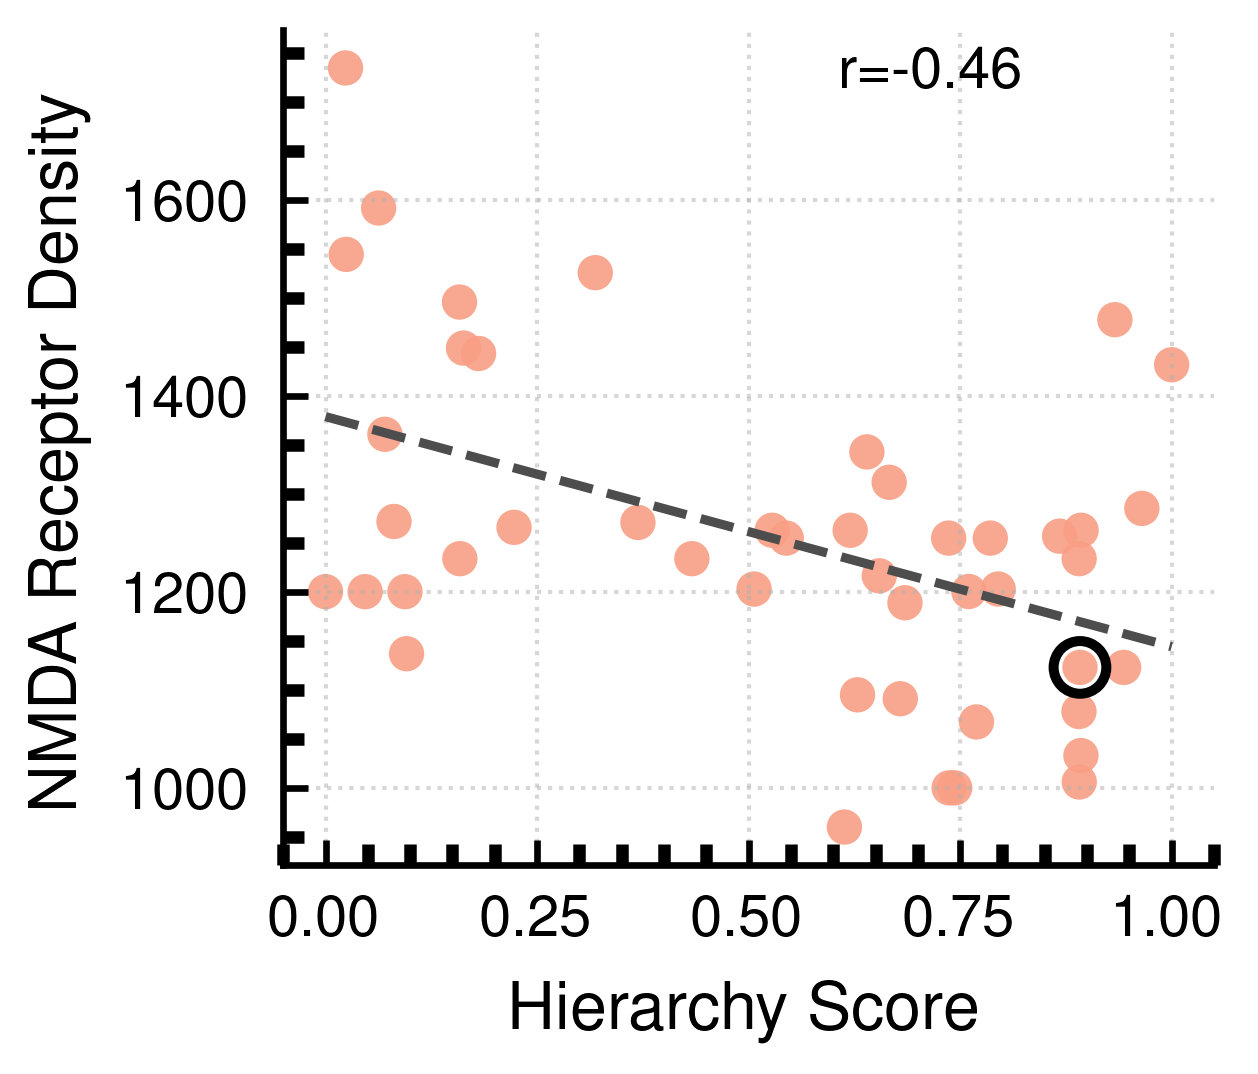

In [26]:
# Fit a simple linear trend line
x = hierarchy_LH_schaefer_100_no_nans
y = nmda_autorad_LH_no_nans
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")
slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
print(f'slope: {slope}, intercept: {intercept}')
nmda_rd_autorad_LH_df = pd.DataFrame({'NMDA_rd': nmda_rd_autorad_LH}) # This includes nan values as well for areas that don't have autoradiography data, which will be replaced next based on hierarchy
for nan_index in indices_nan:
    nmda_rd_autorad_LH_df.loc[nan_index, 'NMDA_rd'] = slope * hierarchy_LH_schaefer_100[nan_index] + intercept
nmda_rd_autorad_LH_df.to_csv('../../data/processed/autorad_schaefer100_LH_NMDA_rd.csv')

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=18, alpha=0.9, color=colors['nmda'], edgecolor='none')
ax.scatter(x[highlight_idx], y[highlight_idx],
           s=40, facecolor='none', edgecolor='black',
           linewidth=1.2, zorder=5)
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color=colors['grey'], linestyle='--', linewidth=1.1,
         label=f"r = {r:.2f}")
ax.set_xlabel('Hierarchy Score', )
ax.set_ylabel('NMDA Receptor Density', )
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.grid(linestyle=':', alpha=0.5)
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
plt.tight_layout()
ax.text(
    0.8, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.savefig('../results/autoradiography_nmda_ampa_schaefer100/NMDA_from_autorad_vs_hierarchy.svg', bbox_inches='tight')
plt.show()

## AMPA receptor density vs. hierarchy

Pearson r = 0.509, p = 0.000307
slope: 161.18685379266273, intercept: 440.3713810184171


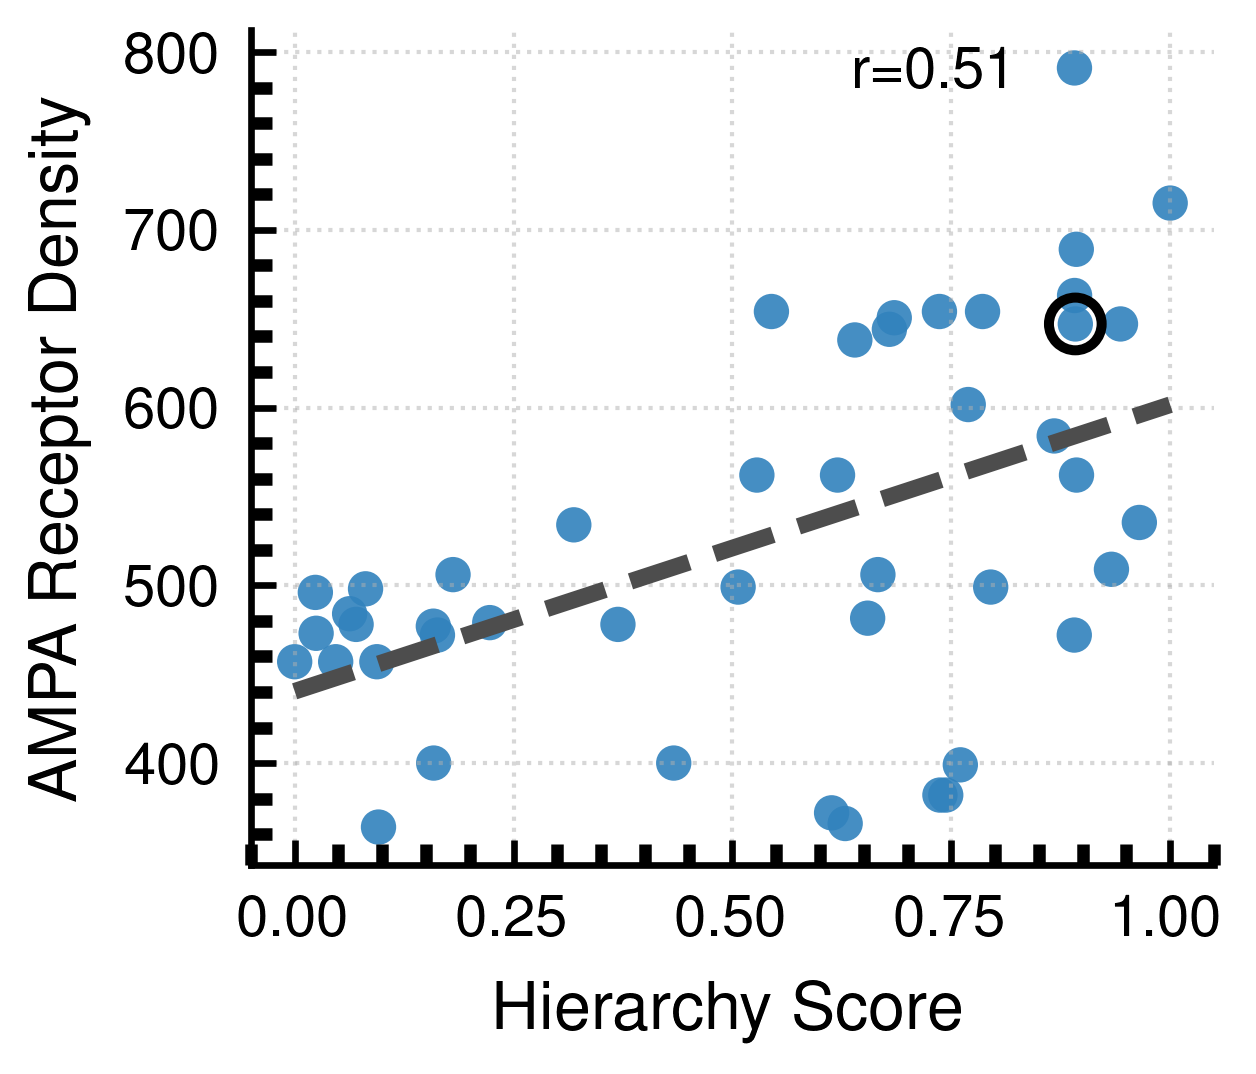

In [27]:
# Fit a simple linear trend line
x = hierarchy_LH_schaefer_100_no_nans
y = ampa_autorad_LH_no_nans
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")

slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
print(f'slope: {slope}, intercept: {intercept}')
ampa_rd_autorad_LH_df = pd.DataFrame({'AMPA_rd': ampa_rd_LH}) # This includes nan values as well, which will be replaced using the hierarchy relationship
for nan_index in indices_nan:
    ampa_rd_autorad_LH_df.loc[nan_index, 'AMPA_rd'] = slope * hierarchy_LH_schaefer_100[nan_index] + intercept
ampa_rd_autorad_LH_df.to_csv('../../data/processed/autorad_schaefer100_LH_AMPA_rd.csv')

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=18, alpha=0.9, color=colors['ampa'], edgecolor='none')
ax.scatter(x[highlight_idx], y[highlight_idx],
           s=40, facecolor='none', edgecolor='black',
           linewidth=1.2, zorder=5)
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color=colors['grey'], linestyle='--', linewidth=2,
         label=f"y = {slope:.2f} x hierarchy + ({intercept:.2f})")
ax.set_xlabel('Hierarchy Score', )
ax.set_ylabel('AMPA Receptor Density', )
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.grid(linestyle=':', alpha=0.5)
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
plt.tight_layout()
ax.text(
    0.8, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.savefig('../results/autoradiography_nmda_ampa_schaefer100/AMPA_from_autorad_vs_hierarchy.svg', bbox_inches='tight')
plt.show()

Pearson r = -0.696, p = 7.8e-08
slope: -1.1175303910333836, intercept: 3.0619028643784305


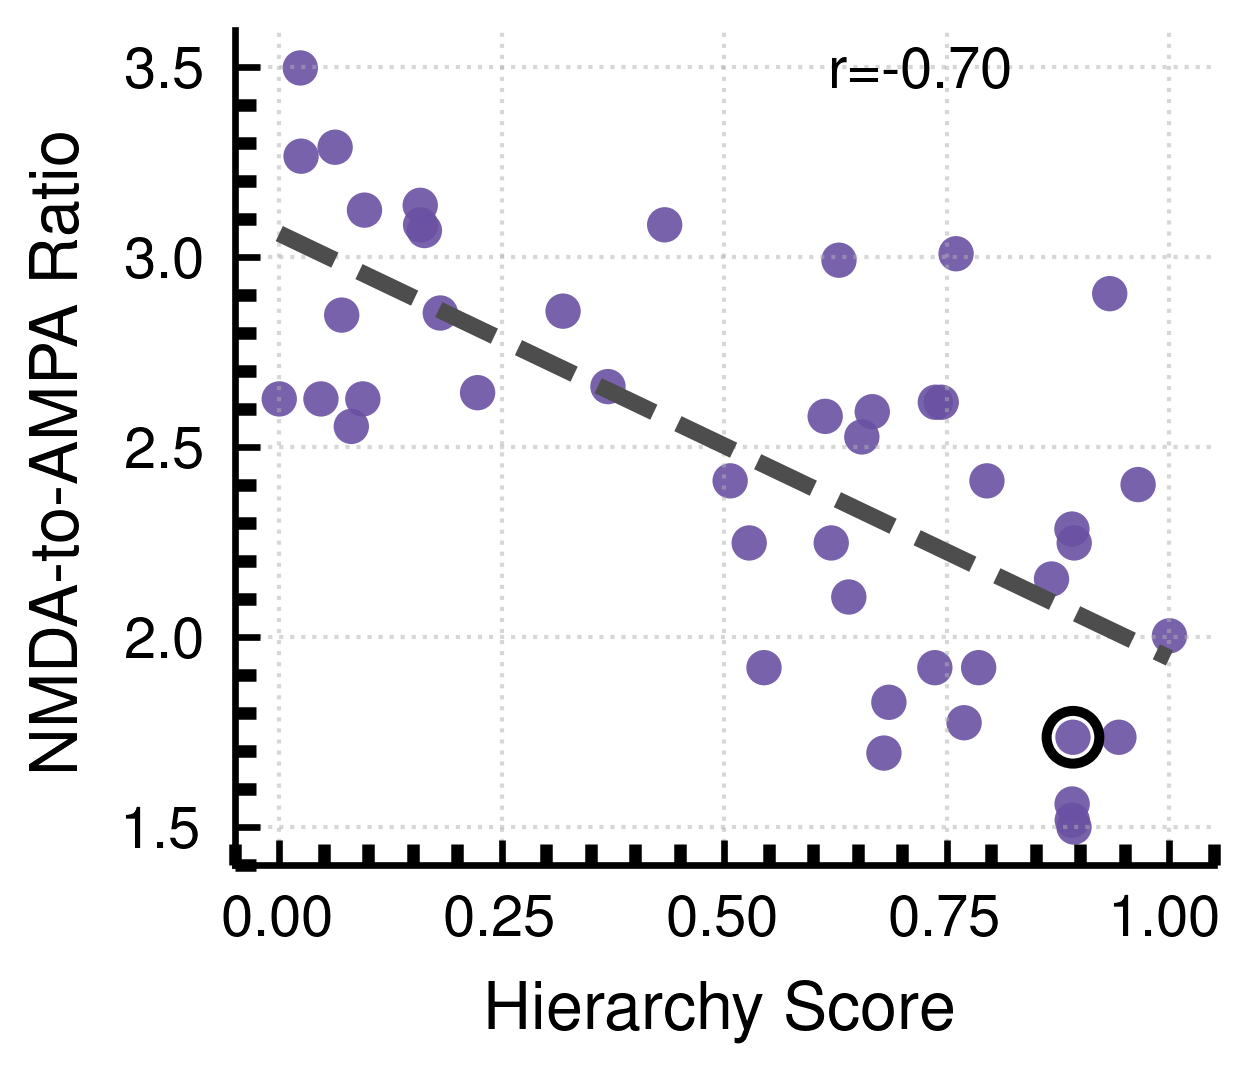

In [28]:
# Fit a simple linear trend line NMDA from autorad and hierarchy
x = hierarchy_LH_schaefer_100_no_nans
y = nmda_to_ampa_LH_no_nans
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")

slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
print(f'slope: {slope}, intercept: {intercept}')

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=18, alpha=0.9, color=colors['ratio'], edgecolor='none')
ax.scatter(x[highlight_idx], y[highlight_idx],
           s=40, facecolor='none', edgecolor='black',
           linewidth=1.2, zorder=5)
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color=colors['grey'], linestyle='--', linewidth=2,
         label=f"y = {slope:.2f} x hierarchy + ({intercept:.2f})")
ax.set_xlabel('Hierarchy Score', )
ax.set_ylabel('NMDA-to-AMPA Ratio', )
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.grid(linestyle=':', alpha=0.5)
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
plt.tight_layout()
ax.text(
    0.8, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.savefig('../results/autoradiography_nmda_ampa_schaefer100/NMDA_to_AMPA_vs_hierarchy.svg', bbox_inches='tight')
plt.show()